In [1]:
import pandas as pd
import numpy  as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
df = pd.read_csv(r"C:\Users\DELL\Practical Deep learning\codmevda_ml_internship_project_lists\Data Set For Task-20260723T182806Z-1-001\Data Set For Task\Supervised\Regression\Stock Prices Data Set.csv")
df.head(10)

,symbol,date,open,high,low,close,volume
0,AAL,02/01/2014,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,02/01/2014,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,02/01/2014,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,02/01/2014,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,02/01/2014,70.1100,70.2300,69.4800,69.8900,1148391
5,ABT,02/01/2014,38.0900,38.4000,38.0000,38.2300,4967472
6,ACN,02/01/2014,81.5000,81.9200,81.0900,81.1300,2405384
7,ADBE,02/01/2014,59.0600,59.5300,58.9400,59.2900,2746370
8,ADI,02/01/2014,49.5200,49.7500,49.0400,49.2800,2799092
9,ADM,02/01/2014,43.2200,43.2900,42.7900,42.9900,2753765


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   symbol  497472 non-null  object 
 1   date    497472 non-null  object 
 2   open    497461 non-null  float64
 3   high    497464 non-null  float64
 4   low     497464 non-null  float64
 5   close   497472 non-null  float64
 6   volume  497472 non-null  int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 26.6+ MB


In [4]:
df.isna().sum()

symbol     0
date       0
open      11
high       8
low        8
close      0
volume     0
dtype: int64

In [5]:
#df['open'] = df['open'].fillna(df['open'].median())
df['high'] = df['high'].fillna(df['high'].median())
df['low'] = df['low'].fillna(df['low'].median())
df.isna().sum()

symbol     0
date       0
open      11
high       0
low        0
close      0
volume     0
dtype: int64

In [6]:
df['date'] = pd.to_datetime(df['date'], format=(r'%d/%m/%Y'))
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 497472 entries, 0 to 497471
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   symbol  497472 non-null  object        
 1   date    497472 non-null  datetime64[ns]
 2   open    497461 non-null  float64       
 3   high    497472 non-null  float64       
 4   low     497472 non-null  float64       
 5   close   497472 non-null  float64       
 6   volume  497472 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 26.6+ MB


In [7]:
df.describe()

,date,open,high,low,close,volume
count,497472,497461.000000,497472.000000,497472.000000,497472.000000,4.974720e+05
mean,2016-01-06 17:16:00.439984896,86.352275,87.132215,85.552127,86.369082,4.253611e+06
min,2014-01-02 00:00:00,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,2015-01-08 00:00:00,41.690000,42.090000,41.280000,41.703750,1.080166e+06
50%,2016-01-11 00:00:00,64.970000,65.560000,64.353700,64.980000,2.084896e+06
75%,2017-01-06 00:00:00,98.410000,99.230000,97.580000,98.420000,4.271928e+06
max,2017-12-29 00:00:00,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08
std,NaN,101.471228,102.311276,100.570184,101.472407,8.232139e+06


In [8]:
df.columns

Index(['symbol', 'date', 'open', 'high', 'low', 'close', 'volume'], dtype='object')

In [9]:
features = ['open', 'high', 'low', 'close']
X = df[features]
scale = StandardScaler()
X_scaled = scale.fit_transform(X)

In [10]:
X_scaled_df = pd.DataFrame(X_scaled, columns = features)

In [11]:
X_scaled_df.isna().sum()

open     11
high      0
low       0
close     0
dtype: int64

In [12]:
X_scaled_df['open'] = X_scaled_df['open'].fillna(X_scaled_df['open'].median())

In [13]:
len(X_scaled_df)

497472

In [14]:
train_X = X_scaled_df.sample(n = 10000, random_state=42)

In [15]:
train_X

,open,high,low,close
367414,0.172835,0.172589,0.178561,0.172864
86606,-0.146369,-0.151520,-0.148873,-0.149786
246299,-0.392449,-0.384828,-0.390694,-0.380982
229761,0.697812,0.684459,0.691536,0.681279
247249,-0.231812,-0.229957,-0.228618,-0.231088
...,...,...,...,...
208749,1.249200,1.261229,1.247467,1.271193
423948,0.067189,0.061262,0.067892,0.064066
139515,-0.251325,-0.252487,-0.248902,-0.251291
174773,-0.034416,-0.038923,-0.030448,-0.037242


In [16]:
rows = []
for k in range(2, 9):
    labs = [KMeans(k, n_init=5, random_state=s).fit(train_X).labels_ for s in (1, 2, 3)]
    rows.append(dict(k = k,
                silhouette = silhouette_score(train_X, labs[0]),
                stability_ari = np.mean([adjusted_rand_score(labs[0], labs[j]) for j in (1, 2)]),
                smallest_cluster = np.bincount(labs[0]).min())
               )
    print(pd.DataFrame(rows).round(3))

c:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\DELL\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\DELL\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

   k  silhouette  stability_ari  smallest_cluster
0  2        0.91            1.0               128
   k  silhouette  stability_ari  smallest_cluster
0  2       0.910          1.000               128
1  3       0.666          0.998               112
   k  silhouette  stability_ari  smallest_cluster
0  2       0.910          1.000               128
1  3       0.666          0.998               112
2  4       0.649          0.992                29
   k  silhouette  stability_ari  smallest_cluster
0  2       0.910          1.000               128
1  3       0.666          0.998               112
2  4       0.649          0.992                29
3  5       0.575          0.720                21
   k  silhouette  stability_ari  smallest_cluster
0  2       0.910          1.000               128
1  3       0.666          0.998               112
2  4       0.649          0.992                29
3  5       0.575          0.720                21
4  6       0.566          0.945                21


In [17]:
import matplotlib.pyplot as plt

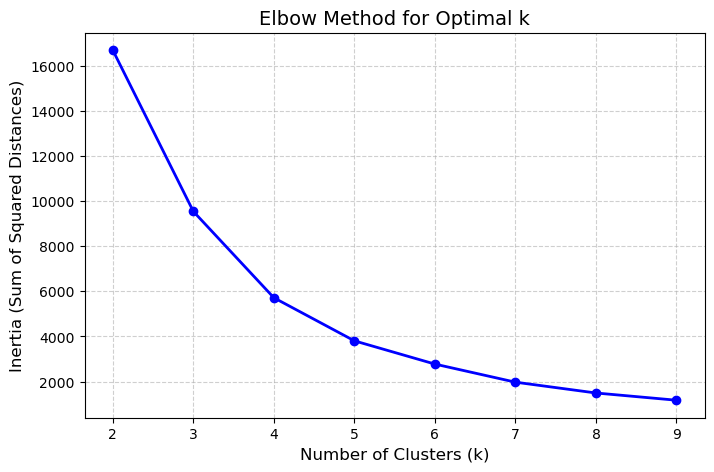

In [18]:
k_values = range(2, 10)
inertias = []

for k in k_values:
    model = KMeans(n_init=5, n_clusters=k, random_state=42)
    model.fit(train_X)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker='o', linestyle='-', color='b', linewidth=2, markersize=6)
plt.title('Elbow Method for Optimal k', fontsize=14)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [19]:
K = 2 
km = KMeans(K, n_init=10, random_state=42).fit(train_X)
labels = km.labels_
print(f'silhouette_score = {silhouette_score(train_X, labels)}')

silhouette_score = 0.9098210390111983
